# Preprocessing Ethereum Historical Data
**Mata kuliah:** Data Mining  
**Pendekatan:** CRISP-DM  
**Catatan:** Jalankan sel dari atas ke bawah. Simpan CSV asli di `data/raw/Ethereum Historical Data.csv`. Jika file belum tersedia (misalnya di Colab), sel berikutnya menyediakan opsi upload.

## 1. Business Understanding
Tujuan realistis: menyiapkan data historis Ethereum untuk eksplorasi pola harga dan eksperimen forecasting harga penutupan (`Price`) pada tanggal berikutnya.

**Batasan:** notebook ini berfokus pada pemahaman dan persiapan data, bukan klaim bahwa model forecasting sudah akurat. Untuk evaluasi model deret waktu, pembagian data harus berdasarkan waktu, bukan pengacakan.

## 2. Data Understanding — memuat data
File menggunakan pemisah titik koma (`;`). Kita pertahankan salinan mentah dan jangan menimpa file asli.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42
RAW_PATH = Path("data/raw/Ethereum Historical Data.csv")
PROCESSED_DIR = Path("data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

if not RAW_PATH.exists():
    # Di Colab, unggah file lalu simpan ke path relatif proyek.
    try:
        from google.colab import files
        uploaded = files.upload()
        if not uploaded:
            raise FileNotFoundError("Tidak ada file yang diunggah.")
        uploaded_name = next(iter(uploaded))
        RAW_PATH.parent.mkdir(parents=True, exist_ok=True)
        RAW_PATH.write_bytes(uploaded[uploaded_name])
    except ImportError as exc:
        raise FileNotFoundError(
            f"File tidak ditemukan: {RAW_PATH}. Letakkan CSV di lokasi tersebut."
        ) from exc

df_raw = pd.read_csv(RAW_PATH, sep=";")
df = df_raw.copy()

print("Shape:", df.shape)
print("\nKolom:", df.columns.tolist())
display(df.head())
df.info()

Shape: (1827, 7)

Kolom: ['Date', 'Price', 'Open', 'High', 'Low', 'Vol.', 'Change %']


,Date,Price,Open,High,Low,Vol.,Change %
0,10/11/2026,"2,502.27","2,506.93","2,513.56","2,498.13",180.82K,-0.17%
1,10/10/2026,"2,506.52","2,487.53","2,519.39","2,486.18",128.91K,0.75%
2,10/09/2026,"2,487.81","2,477.28","2,516.53","2,471.16",186.19K,0.55%
3,10/08/2026,"2,474.30","2,575.38","2,588.35","2,408.36",546.09K,-3.95%
4,10/07/2026,"2,576.16","2,697.30","2,700.08","2,543.77",694.73K,-4.52%


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1827 entries, 0 to 1826
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Date      1827 non-null   object
 1   Price     1827 non-null   object
 2   Open      1827 non-null   object
 3   High      1827 non-null   object
 4   Low       1827 non-null   object
 5   Vol.      1827 non-null   object
 6   Change %  1827 non-null   object
dtypes: object(7)
memory usage: 100.0+ KB


## 2.1 Audit kualitas awal
Hitung missing values, duplikat, dan statistik sebelum perubahan. Karena file dibaca dengan delimiter yang benar, hasil ini lebih dapat dipercaya daripada pembacaan default.

In [2]:
def quality_report(data, label):
    print(f"--- {label} ---")
    print("Shape:", data.shape)
    print("Total missing:", int(data.isna().sum().sum()))
    display(data.isna().sum().rename("missing").to_frame())
    print("Baris duplikat:", int(data.duplicated().sum()))

quality_report(df, "Sebelum preprocessing")
display(df.describe(include="all").T)

--- Sebelum preprocessing ---
Shape: (1827, 7)
Total missing: 0


,missing
Date,0
Price,0
Open,0
High,0
Low,0
Vol.,0
Change %,0


Baris duplikat: 0


,count,unique,top,freq
Date,1827,1827,10/11/2026,1
Price,1827,1820,"1,647.05",2
Open,1827,1822,"1,848.88",2
High,1827,1816,"3,544.71",2
Low,1827,1823,"3,216.48",2
Vol.,1827,1720,1.01M,7
Change %,1827,931,-0.05%,9


## 3. Data Preparation — bersihkan nama kolom dan tipe data
Alasan: nama kolom yang konsisten mempermudah pemanggilan di Python. Tanggal diparse secara eksplisit dengan format bulan/hari/tahun (`%m/%d/%Y`), sedangkan harga menghapus koma pemisah ribuan.

In [3]:
before_shape = df.shape
before_missing = int(df.isna().sum().sum())

df.columns = [c.strip() for c in df.columns]
required = ["Date", "Price", "Open", "High", "Low", "Vol.", "Change %"]
missing_cols = [c for c in required if c not in df.columns]
if missing_cols:
    raise ValueError(f"Kolom wajib tidak ditemukan: {missing_cols}. Kolom aktual: {df.columns.tolist()}")

df["Date"] = pd.to_datetime(df["Date"].astype(str).str.strip(),
                            format="%m/%d/%Y", errors="coerce")

for col in ["Price", "Open", "High", "Low"]:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace(",", "", regex=False).str.strip(),
        errors="coerce"
    )

def parse_volume(value):
    # Konversi K=1.000, M=1.000.000, B=1.000.000.000.
    # Nilai kosong atau format tak dikenal menjadi NaN agar dapat diaudit.
    s = str(value).strip().replace(",", "")
    if s.lower() in {"", "nan", "none", "-", "—"}:
        return np.nan
    match = re.fullmatch(r"([+-]?\d+(?:\.\d+)?)\s*([KMB]?)", s, flags=re.I)
    if not match:
        return np.nan
    number = float(match.group(1))
    suffix = match.group(2).upper()
    multiplier = {"": 1, "K": 1_000, "M": 1_000_000, "B": 1_000_000_000}[suffix]
    return number * multiplier

df["Vol."] = df["Vol."].map(parse_volume)
df["Change %"] = pd.to_numeric(
    df["Change %"].astype(str).str.replace("%", "", regex=False).str.strip(),
    errors="coerce"
)

print("Shape sebelum:", before_shape, "| sesudah:", df.shape)
print("Missing sebelum:", before_missing,
      "| sesudah konversi tipe:", int(df.isna().sum().sum()))
print("Missing per kolom:")
display(df.isna().sum().rename("missing").to_frame())
display(df.head())
df.info()

Shape sebelum: (1827, 7) | sesudah: (1827, 7)
Missing sebelum: 0 | sesudah konversi tipe: 0
Missing per kolom:


,missing
Date,0
Price,0
Open,0
High,0
Low,0
Vol.,0
Change %,0


,Date,Price,Open,High,Low,Vol.,Change %
0,2026-10-11,2502.27,2506.93,2513.56,2498.13,180820.0,-0.17
1,2026-10-10,2506.52,2487.53,2519.39,2486.18,128910.0,0.75
2,2026-10-09,2487.81,2477.28,2516.53,2471.16,186190.0,0.55
3,2026-10-08,2474.30,2575.38,2588.35,2408.36,546090.0,-3.95
4,2026-10-07,2576.16,2697.30,2700.08,2543.77,694730.0,-4.52


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1827 entries, 0 to 1826
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   Date      1827 non-null   datetime64[ns]
 1   Price     1827 non-null   float64       
 2   Open      1827 non-null   float64       
 3   High      1827 non-null   float64       
 4   Low       1827 non-null   float64       
 5   Vol.      1827 non-null   float64       
 6   Change %  1827 non-null   float64       
dtypes: datetime64[ns](1), float64(6)
memory usage: 100.0 KB


## 3.1 Periksa tanggal dan duplikat
Alasan: tanggal invalid dan tanggal ganda dapat mengganggu urutan deret waktu. Baris duplikat dihapus hanya jika seluruh baris benar-benar identik. Tanggal tidak boleh dihapus hanya karena ada harga yang ekstrem.

In [4]:
before_shape = df.shape
before_missing = int(df.isna().sum().sum())
before_duplicates = int(df.duplicated().sum())

invalid_dates = int(df["Date"].isna().sum())
df = df.dropna(subset=["Date"]).copy()
df = df.drop_duplicates().copy()
df = df.sort_values("Date").reset_index(drop=True)

print("Tanggal invalid yang dibuang:", invalid_dates)
print("Duplikat identik yang dibuang:", before_duplicates)
print("Shape sebelum:", before_shape, "| sesudah:", df.shape)
print("Missing sebelum:", before_missing, "| sesudah:", int(df.isna().sum().sum()))
print("Rentang tanggal:", df["Date"].min(), "sampai", df["Date"].max())
print("Tanggal duplikat:", int(df["Date"].duplicated().sum()))

Tanggal invalid yang dibuang: 0
Duplikat identik yang dibuang: 0
Shape sebelum: (1827, 7) | sesudah: (1827, 7)
Missing sebelum: 0 | sesudah: 0
Rentang tanggal: 2021-10-11 00:00:00 sampai 2026-10-11 00:00:00
Tanggal duplikat: 0


## 3.2 Tangani missing values secara konservatif
Alasan: tanggal dan harga OHLC penting untuk analisis. Baris tanpa tanggal tidak dapat dipakai. Untuk volume yang hilang, gunakan median hanya pada salinan data analitik dan catat bahwa ini imputasi, bukan nilai observasi asli. Jangan mengimputasi `Price`, `Open`, `High`, atau `Low` secara otomatis; jika kolom tersebut ternyata missing, hentikan proses dan tinjau baris terkait.

In [5]:
before_shape = df.shape
before_missing = int(df.isna().sum().sum())
critical_cols = ["Price", "Open", "High", "Low", "Change %"]
critical_missing = df[critical_cols].isna().sum()
if critical_missing.any():
    raise ValueError(
        "Ada missing pada kolom inti. Tinjau dulu sebelum memutuskan imputasi: "
        + str(critical_missing[critical_missing > 0].to_dict())
    )

volume_missing_before = int(df["Vol."].isna().sum())
if volume_missing_before:
    volume_median = df["Vol."].median()
    if pd.isna(volume_median):
        raise ValueError("Semua nilai volume missing; median tidak dapat dihitung.")
    df["Vol_missing_flag"] = df["Vol."].isna().astype("int8")
    df["Vol."] = df["Vol."].fillna(volume_median)
else:
    df["Vol_missing_flag"] = 0

print("Shape sebelum:", before_shape, "| sesudah:", df.shape)
print("Missing sebelum:", before_missing, "| sesudah:", int(df.isna().sum().sum()))
print("Volume missing sebelum imputasi:", volume_missing_before)
print("Nilai volume imputasi (median):", df["Vol."].median() if volume_missing_before else "tidak diperlukan")

Shape sebelum: (1827, 7) | sesudah: (1827, 8)
Missing sebelum: 0 | sesudah: 0
Volume missing sebelum imputasi: 0
Nilai volume imputasi (median): tidak diperlukan


## 3.3 Audit konsistensi harga dan volume
Alasan: cek aturan dasar OHLC. Baris yang melanggar ditandai untuk investigasi, bukan langsung dihapus. Volume hasil parsing dinyatakan dalam satuan dasar hasil konversi suffix; makna ekonomi/unit asli perlu mengikuti dokumentasi sumber data.

In [6]:
before_shape = df.shape
before_missing = int(df.isna().sum().sum())

df["flag_high_below_low"] = (df["High"] < df["Low"]).astype("int8")
df["flag_close_outside_range"] = (
    (df["Price"] < df["Low"]) | (df["Price"] > df["High"])
).astype("int8")
df["flag_negative_ohlc"] = (df[["Price", "Open", "High", "Low"]] < 0).any(axis=1).astype("int8")

print("High < Low:", int(df["flag_high_below_low"].sum()))
print("Price di luar Low–High:", int(df["flag_close_outside_range"].sum()))
print("Harga OHLC negatif:", int(df["flag_negative_ohlc"].sum()))
print("Shape sebelum:", before_shape, "| sesudah:", df.shape)
print("Missing sebelum:", before_missing, "| sesudah:", int(df.isna().sum().sum()))

High < Low: 0
Price di luar Low–High: 0
Harga OHLC negatif: 0
Shape sebelum: (1827, 8) | sesudah: (1827, 11)
Missing sebelum: 0 | sesudah: 0


## 3.4 Outlier dengan metode IQR
Alasan: IQR digunakan untuk menandai nilai yang jauh dari sebaran utama. Pada harga kripto, nilai ekstrem bisa merupakan kejadian pasar yang valid. Karena itu, notebook menambahkan flag outlier dan tidak menghapus atau memangkas nilainya secara otomatis.

In [7]:
before_shape = df.shape
before_missing = int(df.isna().sum().sum())
outlier_summary = []

for col in ["Price", "Open", "High", "Low", "Vol.", "Change %"]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    flag_col = f"outlier_iqr_{col.replace('%', 'pct').replace('.', '').replace(' ', '_')}"
    df[flag_col] = ((df[col] < lower) | (df[col] > upper)).astype("int8")
    outlier_summary.append({
        "kolom": col, "batas_bawah": lower, "batas_atas": upper,
        "jumlah_flag": int(df[flag_col].sum())
    })

display(pd.DataFrame(outlier_summary))
print("Shape sebelum:", before_shape, "| sesudah penambahan flag:", df.shape)
print("Missing sebelum:", before_missing, "| sesudah:", int(df.isna().sum().sum()))

,kolom,batas_bawah,batas_atas,jumlah_flag
0,Price,-169.1675,5.108373e+03,0
1,Open,-172.8075,5.114453e+03,0
2,High,-230.7825,5.288198e+03,0
3,Low,-140.9650,4.976955e+03,0
4,Vol.,-253160.0000,1.228480e+06,120
5,Change %,-6.8825,6.857500e+00,117


Shape sebelum: (1827, 11) | sesudah penambahan flag: (1827, 17)
Missing sebelum: 0 | sesudah: 0


## 3.5 Feature engineering tanggal
Alasan: hari dalam minggu dan bulan dapat membantu eksplorasi pola kalender. Fitur ini tidak menggantikan tanggal asli. Untuk model forecasting, fitur dan target harus dibentuk tanpa memakai informasi masa depan.

In [8]:
before_shape = df.shape
before_missing = int(df.isna().sum().sum())

df["year"] = df["Date"].dt.year
df["month"] = df["Date"].dt.month
df["day_of_week"] = df["Date"].dt.dayofweek

print("Shape sebelum:", before_shape, "| sesudah:", df.shape)
print("Missing sebelum:", before_missing, "| sesudah:", int(df.isna().sum().sum()))
display(df[["Date", "Price", "year", "month", "day_of_week"]].head())

Shape sebelum: (1827, 17) | sesudah: (1827, 20)
Missing sebelum: 0 | sesudah: 0


,Date,Price,year,month,day_of_week
0,2021-10-11,3545.06,2021,10,0
1,2021-10-12,3489.90,2021,10,1
2,2021-10-13,3607.28,2021,10,2
3,2021-10-14,3790.41,2021,10,3
4,2021-10-15,3866.90,2021,10,4


## 3.6 Visualisasi ringkas
Alasan: grafik membantu mendeteksi tren, lonjakan, dan nilai yang perlu ditinjau. Grafik bukan bukti bahwa sebuah nilai salah.

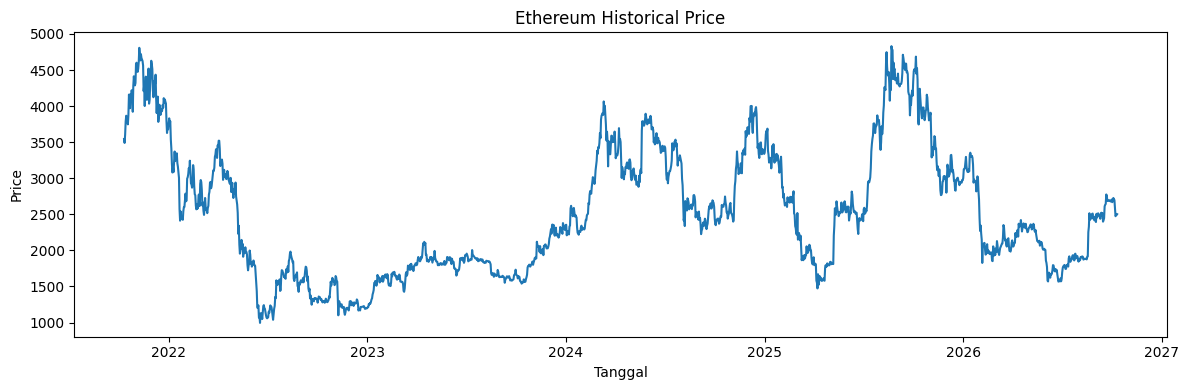

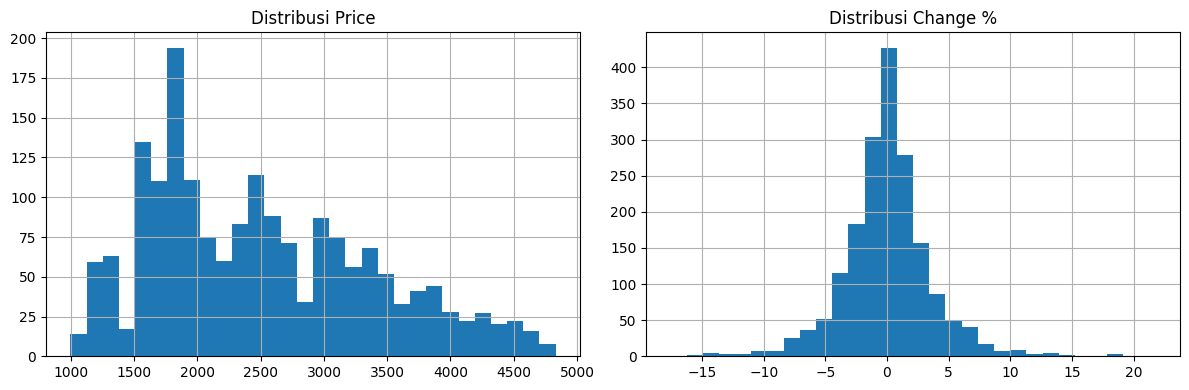

In [9]:
plt.figure(figsize=(12, 4))
plt.plot(df["Date"], df["Price"])
plt.title("Ethereum Historical Price")
plt.xlabel("Tanggal")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["Price"].hist(ax=axes[0], bins=30)
axes[0].set_title("Distribusi Price")
df["Change %"].hist(ax=axes[1], bins=30)
axes[1].set_title("Distribusi Change %")
plt.tight_layout()
plt.show()

## 3.7 Scaling untuk eksperimen model (opsional)
Scaling bukan keharusan untuk menyimpan dataset hasil cleaning. Terapkan pada fitur numerik yang dipilih untuk model; `Date` tidak diskalakan. Simpan hasil scaling terpisah agar interpretasi harga asli tetap terjaga. Di bawah ini scaler hanya di-fit pada 80% data paling awal untuk menghindari kebocoran informasi dari masa depan.

In [10]:
from sklearn.preprocessing import StandardScaler

numeric_features = ["Open", "High", "Low", "Vol.", "Change %"]
split_idx = int(len(df) * 0.8)
if split_idx < 2:
    raise ValueError("Data terlalu sedikit untuk split temporal.")

scaler = StandardScaler()
scaled_train = scaler.fit_transform(df.loc[:split_idx-1, numeric_features])
scaled_test = scaler.transform(df.loc[split_idx:, numeric_features])

scaled_cols = [f"{c}_scaled" for c in numeric_features]
scaled_df = pd.DataFrame(
    np.vstack([scaled_train, scaled_test]),
    columns=scaled_cols,
    index=df.index
)
df_model = pd.concat([df.copy(), scaled_df], axis=1)

print("Data untuk model:", df_model.shape)
print("Jumlah baris train:", split_idx, "| test:", len(df) - split_idx)
print("Missing data model:", int(df_model.isna().sum().sum()))

Data untuk model: (1827, 25)
Jumlah baris train: 1461 | test: 366
Missing data model: 0


## 3.8 Simpan hasil
Dua output dibuat: dataset hasil cleaning dengan nilai harga asli dan flag audit, serta versi eksperimen dengan fitur yang sudah diskalakan. File mentah tidak ditimpa.

In [11]:
clean_path = PROCESSED_DIR / "ethereum_cleaned.csv"
model_path = PROCESSED_DIR / "ethereum_model_ready.csv"

df.to_csv(clean_path, index=False)
df_model.to_csv(model_path, index=False)

print("Tersimpan:", clean_path)
print("Tersimpan:", model_path)
print("\nRingkasan akhir")
print("Shape cleaned:", df.shape)
print("Missing cleaned:", int(df.isna().sum().sum()))
print("Duplikat cleaned:", int(df.duplicated().sum()))
print("Shape model-ready:", df_model.shape)
print("Missing model-ready:", int(df_model.isna().sum().sum()))

Tersimpan: data/processed/ethereum_cleaned.csv
Tersimpan: data/processed/ethereum_model_ready.csv

Ringkasan akhir
Shape cleaned: (1827, 20)
Missing cleaned: 0
Duplikat cleaned: 0
Shape model-ready: (1827, 25)
Missing model-ready: 0


## 4. Evaluasi hasil preprocessing
Bandingkan laporan awal dan akhir. Keputusan penting:
- Delimiter `;` dipakai karena sesuai file.
- Harga dibersihkan dari pemisah ribuan dan dikonversi ke numerik.
- Volume K/M/B dikonversi dengan pengali yang sesuai.
- Duplikat identik dihapus jika ada; nilai ekstrem tidak dihapus otomatis.
- Missing volume diimputasi median hanya bila benar-benar ada setelah parsing, dengan flag penanda.
- Encoding kategori tidak diterapkan karena dataset ini tidak memiliki kolom kategorikal biasa setelah tanggal diparse. Tanggal diubah menjadi fitur kalender.
- Scaling disediakan sebagai output opsional untuk model, bukan mengganti nilai harga asli.